# 6. Характер травмы (Nature): что случилось с организмом

Данные: `OSHA_db`, 105 996 тяжёлых травм (январь 2015 – ноябрь 2025). SQL-запросы — `SQL/06_nature.sql`.

99,6% кодов Nature относятся к разделу 1 «Травмы», поэтому деление по первой цифре бесполезно. Как и в SQL, используются:
- рейтинг по названию (одинаковые названия под разными кодами объединены) — 6.1;
- укрупнённые категории по ключевым словам (перелом, ампутация, ожог …) — 6.2–6.5; правила те же, что в SQL (`src/labels.py`, `NATURE_CATEGORIES`).

Что добавляет Python: тяжесть по категориям с 95% ДИ, связь категории с частью тела и типом происшествия (χ², V Крамера), динамика по годам.

In [1]:
import os
if not os.path.isdir("src"):  # ноутбук запущен из notebooks/, а не из Analysis/
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy import stats

from src.db import query
from src.viz import set_style, tr, finish, barh_ranked, wrap, LANGS, TABLES_DIR, MAIN, ACCENT, SERIES
from src.stats import num, cramers_v, share_ci, rank_by_title
from src.labels import (norm_title, nature_ru, nature_category, body_part_ru, NATURE_CATEGORIES,
                        NATURE_OTHER, BODY_DIVISIONS, EVENT_DIVISIONS)

set_style()
TABLES_DIR.mkdir(exist_ok=True)

## 6.0. Исходные данные

In [2]:
cases = query("""
    SELECT i.id,
           EXTRACT(YEAR FROM i.event_date)::int AS year,
           i.nature_code,
           n.title                              AS nature,
           i.part_of_body_code,
           b.title                              AS body_part,
           i.event_code,
           i.severity_code
    FROM injuries i
    JOIN nature_lookup    n ON n.code = i.nature_code
    JOIN body_part_lookup b ON b.code = i.part_of_body_code
""")
cat = cases["nature"].map(nature_category)
cases["category_ru"] = cat.str[0]
cases["category_en"] = cat.str[1]
cases["body_div"] = cases["part_of_body_code"].astype(str).str[0]
cases["event_div"] = cases["event_code"].astype(str).str[0]
cases["hospitalization"] = (cases["severity_code"] & 4) > 0
cases["amputation"] = (cases["severity_code"] & 2) > 0

CAT_EN = dict(cases[["category_ru", "category_en"]].drop_duplicates().to_numpy())
N = len(cases)
print(f"Случаев: {num(N)}")
cases.head()

Случаев: 105 996


,id,year,nature_code,nature,part_of_body_code,body_part,event_code,severity_code,category_ru,category_en,body_div,event_div,hospitalization,amputation
0,931176,2015,111,Fractures,513,Lower leg(s),1214,4,Переломы,Fractures,5,1,True,False
1,930267,2015,1522,Second degree heat (thermal) burns,519,"Leg(s), n.e.c.",317,4,Ожоги,Burns,5,3,True,False
2,929823,2015,10,"Traumatic injuries and disorders, unspecified",9999,Nonclassifiable,4331,4,Прочее,Other,9,4,True,False
3,929711,2015,1972,"Soreness, pain, hurt-nonspecified injury",510,"Leg(s), unspecified",640,4,Боль без уточнения,Unspecified pain,5,6,True,False
4,929642,2015,111,Fractures,4429,"Finger(s), fingernail(s), n.e.c.",6411,4,Переломы,Fractures,4,6,True,False


## 6.1. Топ-15 видов травм

«Fractures» встречается под кодами 111 и 124, «Amputations» — под разными кодами разных редакций; одинаковые названия объединены.

In [3]:
top = rank_by_title(cases["nature"], cases["nature_code"])
top["nature_ru"] = top["title"].map(nature_ru)
top = top.reset_index(drop=True)[["title", "nature_ru", "codes", "cases", "pct"]]
top.index += 1

top.head(20).round(2).to_csv(TABLES_DIR / "06_1_top_nature.csv", encoding="utf-8-sig")
top.head(20).round(2)

,title,nature_ru,codes,cases,pct
1,Fractures,Переломы,"111, 124",35073,33.09
2,Amputations,Ампутации,1311,23462,22.13
3,"Soreness, pain, hurt-nonspecified injury",Боль без уточнения травмы,1972,6522,6.15
4,"Cuts, lacerations","Порезы, рваные раны",132,5238,4.94
5,"Amputations, avulsions, enucleations unspecified","Ампутации, отрывы (не уточнено)","1220, 1310",2933,2.77
6,"Heat (thermal) burns, unspecified",Термические ожоги,1520,2104,1.98
7,"Intracranial injuries, unspecified",Внутричерепные травмы,"160, 1110",2021,1.91
8,"Traumatic injuries and disorders, unspecified",Травмы (не уточнено),10,1729,1.63
9,Crushing injuries,Размозжения,1971,1723,1.63
10,Amputations involving bone loss,Ампутации с потерей кости,1221,1518,1.43


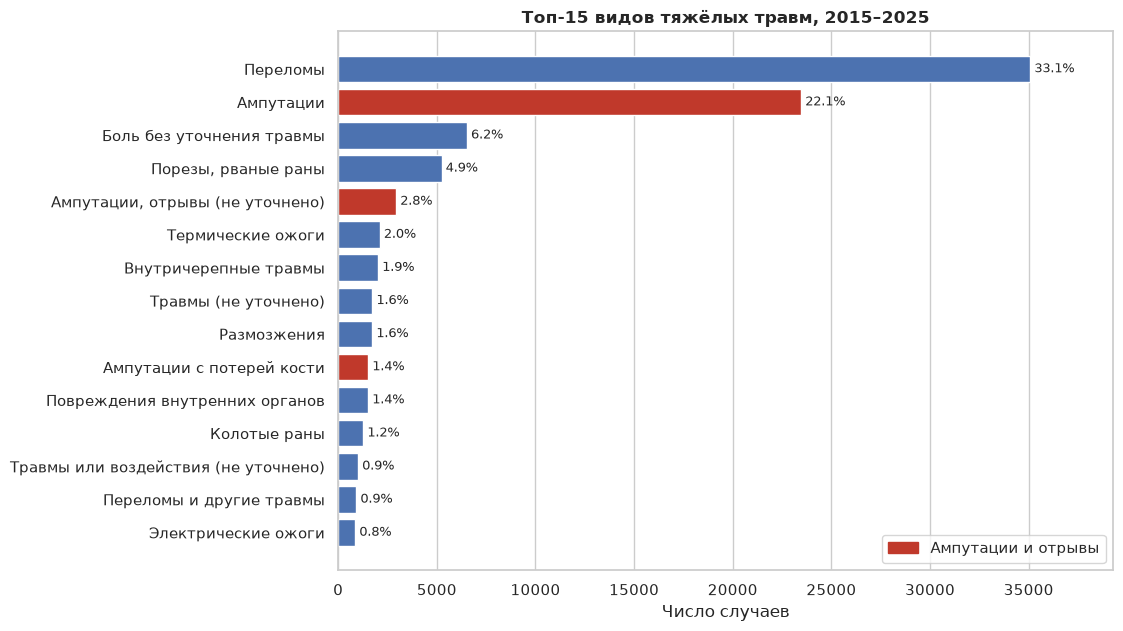

Первые два вида (переломы и ампутации) дают 55.2% всех случаев


In [4]:
t = top.head(15)
amp = t["title"].str.contains("amputat|avulsion", case=False)
for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 7))
    barh_ranked(ax, t["nature_ru"] if lang == "ru" else t["title"], t["cases"],
                notes=[f"{p:.1f}%" for p in t["pct"]], color=np.where(amp, ACCENT, MAIN))
    ax.set_title(tr("Топ-15 видов тяжёлых травм, 2015–2025", "Top 15 kinds of severe injury, 2015–2025", lang))
    ax.set_xlabel(tr("Число случаев", "Number of cases", lang))
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ACCENT)],
              labels=[tr("Ампутации и отрывы", "Amputations and avulsions", lang)], loc="lower right")
    finish(fig, "06_1_top_nature", lang)

print(f"Первые два вида (переломы и ампутации) дают {t['pct'].head(2).sum():.1f}% всех случаев")

## 6.2. Укрупнённые категории травм и их тяжесть

Доли госпитализации и ампутации — с 95% ДИ Уилсона. Для ампутаций доля госпитализаций намного ниже: по правилам OSHA об ампутации сообщают отдельно, даже если пострадавшего не госпитализировали.

In [5]:
rows = []
for c, g in cases.groupby("category_ru"):
    h, h_lo, h_hi = share_ci(g["hospitalization"].sum(), len(g))
    a, a_lo, a_hi = share_ci(g["amputation"].sum(), len(g))
    rows.append({"category_ru": c, "category_en": CAT_EN[c], "cases": len(g), "pct_of_all": 100 * len(g) / N,
                 "pct_hospitalized": h, "hosp_ci_low": h_lo, "hosp_ci_high": h_hi,
                 "pct_amputation": a, "amp_ci_low": a_lo, "amp_ci_high": a_hi})
cats = pd.DataFrame(rows).sort_values("cases", ascending=False).reset_index(drop=True)
cats.index += 1

cats.round(2).to_csv(TABLES_DIR / "06_2_nature_categories.csv", encoding="utf-8-sig")
cats[["category_ru", "cases", "pct_of_all", "pct_hospitalized", "pct_amputation"]].round(2)

,category_ru,cases,pct_of_all,pct_hospitalized,pct_amputation
1,Переломы,38359,36.19,99.91,0.22
2,Ампутации,28685,27.06,30.10,96.60
3,Прочее,8163,7.70,99.90,0.26
4,"Раны (порезы, проколы)",6715,6.34,99.67,0.69
5,Боль без уточнения,6538,6.17,99.74,0.60
6,Ожоги,5991,5.65,99.95,0.18
7,Черепно-мозговые травмы,3476,3.28,100.00,0.03
8,Тепловой удар / перегрев,2658,2.51,100.00,0.04
9,Размозжения,2039,1.92,99.36,1.52
10,Внутренние повреждения,1998,1.88,99.80,0.65


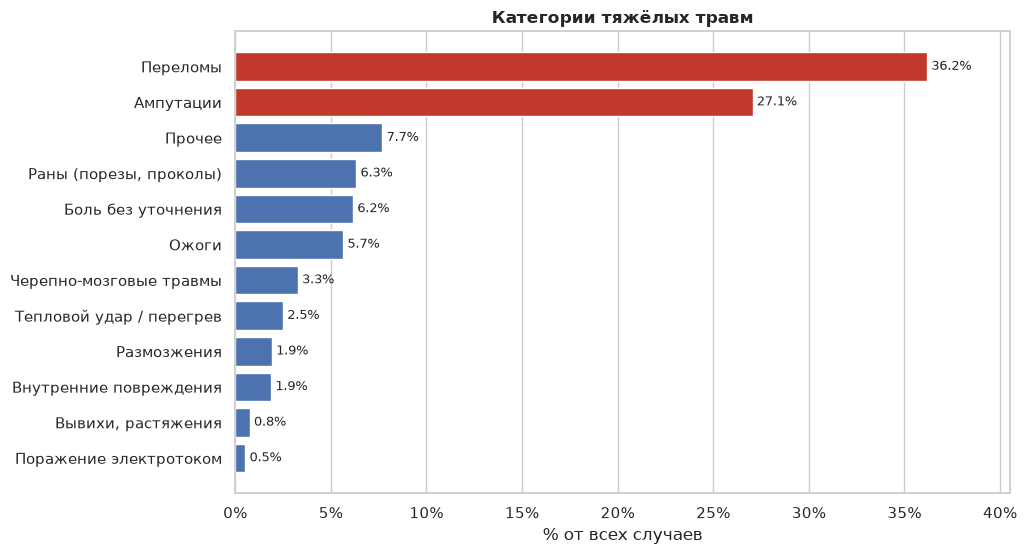

In [6]:
for lang in LANGS:
    labels = cats["category_ru"] if lang == "ru" else cats["category_en"]
    fig, ax = plt.subplots(figsize=(10, 6))
    barh_ranked(ax, labels, cats["pct_of_all"], notes=[f"{p:.1f}%" for p in cats["pct_of_all"]],
                color=np.where(cats["category_ru"].isin(["Переломы", "Ампутации"]), ACCENT, MAIN))
    ax.set_title(tr("Категории тяжёлых травм", "Categories of severe injuries", lang))
    ax.set_xlabel(tr("% от всех случаев", "% of all cases", lang))
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    finish(fig, "06_2_nature_categories", lang)

## 6.3. Категория травмы × часть тела

SQL-запрос 6.3 даёт топ-3 части тела для каждой категории. Здесь — то же с объединёнными названиями частей тела и тепловая карта по разделам тела.

In [7]:
cases["body_key"] = cases["body_part"].map(norm_title)
bp = (cases.groupby(["category_ru", "body_key"]).size().rename("cases").reset_index()
      .sort_values(["category_ru", "cases"], ascending=[True, False]))
bp["pct_within_category"] = 100 * bp["cases"] / bp.groupby("category_ru")["cases"].transform("sum")
bp["place"] = bp.groupby("category_ru").cumcount() + 1
names = rank_by_title(cases["body_part"], cases["part_of_body_code"])["title"]
bp["body_part"] = bp["body_key"].map(names)
bp["body_part_ru"] = bp["body_part"].map(body_part_ru)
top3 = (bp[bp["place"] <= 3].set_index(["category_ru", "place"])
        [["body_part_ru", "body_part", "cases", "pct_within_category"]]
        .reindex(cats["category_ru"], level=0))

top3.round(2).to_csv(TABLES_DIR / "06_3_category_top3_body_parts.csv", encoding="utf-8-sig")
top3.round(1)

body_part_ru  \
category_ru              place                                          
Переломы                 1                         Ноги (не уточнено)   
                         2                      Тазобедренная область   
                         3                                    Лодыжки   
Ампутации                1                            Кончики пальцев   
                         2                     Пальцы, ногти (прочее)   
                         3                Пальцы, ногти (не уточнено)   
Прочее                   1                        Не классифицировано   
                         2                          Системы организма   
                         3                         Спина, позвоночник   
Раны (порезы, проколы)   1                Пальцы, ногти (не уточнено)   
                         2                    Кисти рук (не уточнено)   
                         3                                 Предплечья   
Боль без уточнения       1                         Спина, позвоночник   
                         2             Несколько частей тела (прочее)   
                         3                         Ноги (не уточнено)   
Ожоги                    1             Несколько частей тела (прочее)   
                         2                        Не классифицировано   
                         3                    Кисти рук (не уточнено)   
Черепно-мозговые травмы  1                              Головной мозг   
                         2                          Системы организма   
                         3                          Голова и туловище   
Тепловой удар / перегрев 1                          Системы организма   
                         2      Системы организма и другие части тела   
                         3                              Головной мозг   
Размозжения              1                Пальцы, ногти (не уточнено)   
                         2                    Кисти рук (не уточнено)   
                         3                     Пальцы, ногти (прочее)   
Внутренние повреждения   1                             Грудная клетка   
                         2                                      Живот   
                         3                Несколько областей туловища   
Вывихи, растяжения       1                    Плечи, ключицы, лопатки   
                         2                         Спина, позвоночник   
                         3                                     Колени   
Поражение электротоком   1                          Системы организма   
                         2      Системы организма и другие части тела   
                         3                 Кисти и руки (не уточнено)   

                                                                        body_part  \
category_ru              place                                                      
Переломы                 1                                    Leg(s), unspecified   
                         2                                                 Hip(s)   
                         3                                               Ankle(s)   
Ампутации                1                                           Fingertip(s)   
                         2                       Finger(s), fingernail(s), n.e.c.   
                         3                  Finger(s), fingernail(s), unspecified   
Прочее                   1                                        Nonclassifiable   
                         2                                           BODY SYSTEMS   
                         3        Back, including spine, spinal cord, unspecified   
Раны (порезы, проколы)   1                  Finger(s), fingernail(s), unspecified   
                         2                                   Hand(s), unspecified   
                         3                                             Forearm(s)   
Боль без уточнения       1        Back, including spine, spinal cord, unspecified   
       

Категория травмы × раздел тела: χ² = 196 597, df = 77, p = 0.00e+00, V Крамера = 0.515


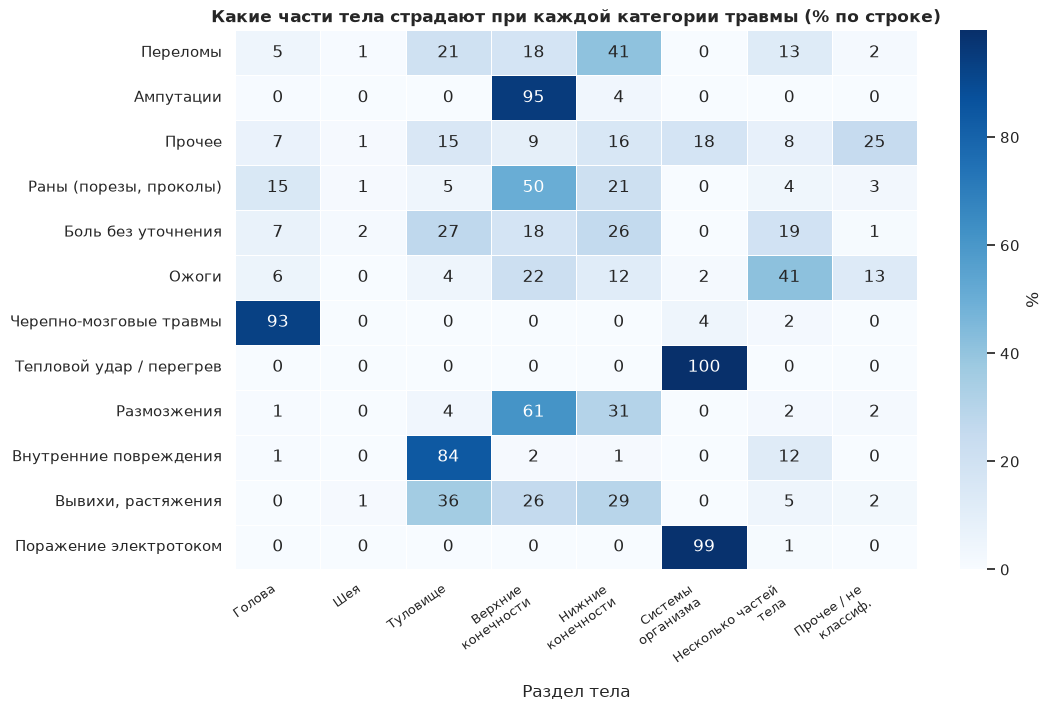

In [8]:
ct = pd.crosstab(cases["category_ru"], cases["body_div"]).loc[cats["category_ru"]]
chi2, p, dof, v, _ = cramers_v(ct)
print(f"Категория травмы × раздел тела: χ² = {num(chi2)}, df = {dof}, p = {p:.2e}, V Крамера = {v:.3f}")

row_pct = ct.div(ct.sum(axis=1), axis=0) * 100
row_pct.round(1).to_csv(TABLES_DIR / "06_3_category_body_division_row_pct.csv", encoding="utf-8-sig")

for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, ax = plt.subplots(figsize=(11, 7))
    sns.heatmap(row_pct, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "%"},
                linewidths=0.5, linecolor="white", ax=ax,
                xticklabels=[wrap(BODY_DIVISIONS[d][k], 16) for d in row_pct.columns],
                yticklabels=row_pct.index if lang == "ru" else [CAT_EN[c] for c in row_pct.index])
    ax.set_title(tr("Какие части тела страдают при каждой категории травмы (% по строке)",
                    "Body divisions affected by each injury category (row %)", lang))
    ax.set_xlabel(tr("Раздел тела", "Body division", lang))
    ax.set_ylabel("")
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right", fontsize=9)
    finish(fig, "06_3_category_body_division", lang)

## 6.4. Категория травмы × тип происшествия

Связка с `SQL/05_events.sql`: при каких происшествиях возникает каждая категория травмы.

Категория травмы × раздел типа происшествия: χ² = 148 349, df = 77, p = 0.00e+00, V Крамера = 0.447


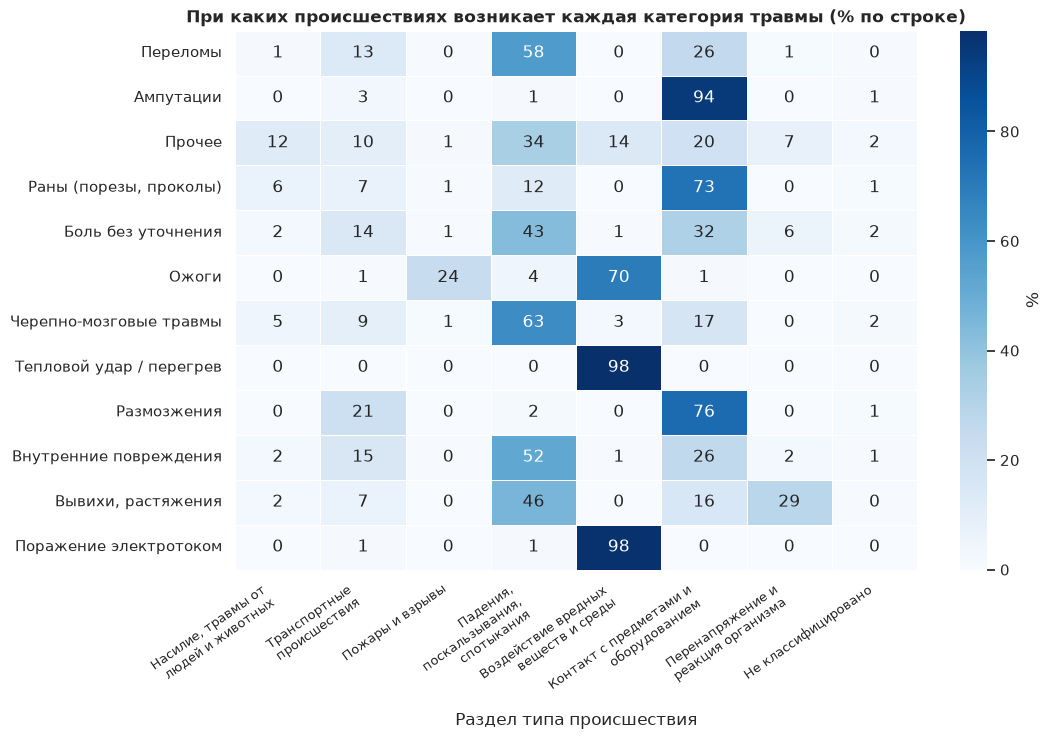

In [9]:
ct = pd.crosstab(cases["category_ru"], cases["event_div"]).loc[cats["category_ru"]]
chi2, p, dof, v, _ = cramers_v(ct)
print(f"Категория травмы × раздел типа происшествия: χ² = {num(chi2)}, df = {dof}, p = {p:.2e}, V Крамера = {v:.3f}")

row_pct = ct.div(ct.sum(axis=1), axis=0) * 100
row_pct.round(1).to_csv(TABLES_DIR / "06_4_category_event_division_row_pct.csv", encoding="utf-8-sig")

for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, ax = plt.subplots(figsize=(11, 7))
    sns.heatmap(row_pct, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "%"},
                linewidths=0.5, linecolor="white", ax=ax,
                xticklabels=[wrap(EVENT_DIVISIONS[d][k], 22) for d in row_pct.columns],
                yticklabels=row_pct.index if lang == "ru" else [CAT_EN[c] for c in row_pct.index])
    ax.set_title(tr("При каких происшествиях возникает каждая категория травмы (% по строке)",
                    "Event divisions behind each injury category (row %)", lang))
    ax.set_xlabel(tr("Раздел типа происшествия", "Event division", lang))
    ax.set_ylabel("")
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right", fontsize=9)
    finish(fig, "06_4_category_event_division", lang)

## 6.5. Категории травм по годам

2025 год неполный, но доли от этого не искажаются.

**Смена классификации.** С 2024 года используется новая редакция OIICS: кода *Soreness, pain, hurt-nonspecified injury* в ней нет (такие случаи уходят в *Traumatic injuries or exposures unspecified* → категория «Прочее»), а поражение электротоком объединено с электроожогами (*Electrical burns and electrocution* → «Ожоги»). Кроме того, в 2015 году завышены «Прочее» и «Боль без уточнения» (как и «не классифицировано» в разделе 1). Поэтому линейные тренды считаются по сопоставимому периоду **2016–2023**, а 2015 и 2024–2025 показаны на графике для полноты.

In [10]:
by_year = pd.crosstab(cases["year"], cases["category_ru"], normalize="index")[cats["category_ru"]] * 100
by_year.round(2).to_csv(TABLES_DIR / "06_5_categories_by_year.csv", encoding="utf-8-sig")

chi2, p, dof, v, _ = cramers_v(pd.crosstab(cases["year"], cases["category_ru"]))
print(f"Категория травмы × год: χ² = {num(chi2)}, df = {dof}, p = {p:.2e}, V Крамера = {v:.3f}\n")
comparable = by_year.loc[2016:2023]
for c in cats["category_ru"].head(8):
    lr = stats.linregress(comparable.index, comparable[c])
    print(f"{c:<26} наклон {lr.slope:+.2f} п.п. в год, R² = {lr.rvalue**2:.2f}, p = {lr.pvalue:.3f}")
by_year.round(1)

Категория травмы × год: χ² = 3 214, df = 110, p = 0.00e+00, V Крамера = 0.055

Переломы                   наклон +0.62 п.п. в год, R² = 0.74, p = 0.006
Ампутации                  наклон -0.03 п.п. в год, R² = 0.02, p = 0.758
Прочее                     наклон -0.21 п.п. в год, R² = 0.77, p = 0.004
Раны (порезы, проколы)     наклон -0.13 п.п. в год, R² = 0.57, p = 0.031
Боль без уточнения         наклон -0.14 п.п. в год, R² = 0.36, p = 0.114
Ожоги                      наклон +0.06 п.п. в год, R² = 0.21, p = 0.255
Черепно-мозговые травмы    наклон -0.03 п.п. в год, R² = 0.08, p = 0.495
Тепловой удар / перегрев   наклон -0.09 п.п. в год, R² = 0.18, p = 0.293


category_ru,Переломы,Ампутации,Прочее,"Раны (порезы, проколы)",Боль без уточнения,Ожоги,Черепно-мозговые травмы,Тепловой удар / перегрев,Размозжения,Внутренние повреждения,"Вывихи, растяжения",Поражение электротоком
year,,,,,,,,,,,,
2015,26.7,28.1,11.3,6.4,12.1,5.3,3.4,2.3,1.9,1.1,0.6,0.8
2016,33.5,27.4,7.0,6.6,8.0,5.4,3.2,3.4,2.1,1.8,0.7,0.7
2017,34.3,28.0,6.8,6.9,7.0,5.4,3.8,2.2,2.3,1.7,0.8,0.7
2018,36.8,26.6,7.1,6.7,6.2,5.4,3.4,2.7,1.8,2.0,0.8,0.7
2019,36.1,26.4,6.4,6.6,6.9,5.9,3.7,2.9,1.8,1.9,0.8,0.6
2020,38.0,27.0,6.1,6.8,6.5,5.0,3.6,2.1,1.8,1.8,0.8,0.5
2021,38.1,26.9,6.1,6.5,6.8,5.5,3.2,2.0,1.8,1.9,0.7,0.5
2022,37.7,26.8,6.3,6.3,6.5,5.8,3.4,2.2,2.0,1.6,0.9,0.6
2023,37.6,27.7,5.4,5.5,6.5,6.0,3.3,2.8,1.9,1.9,1.0,0.6


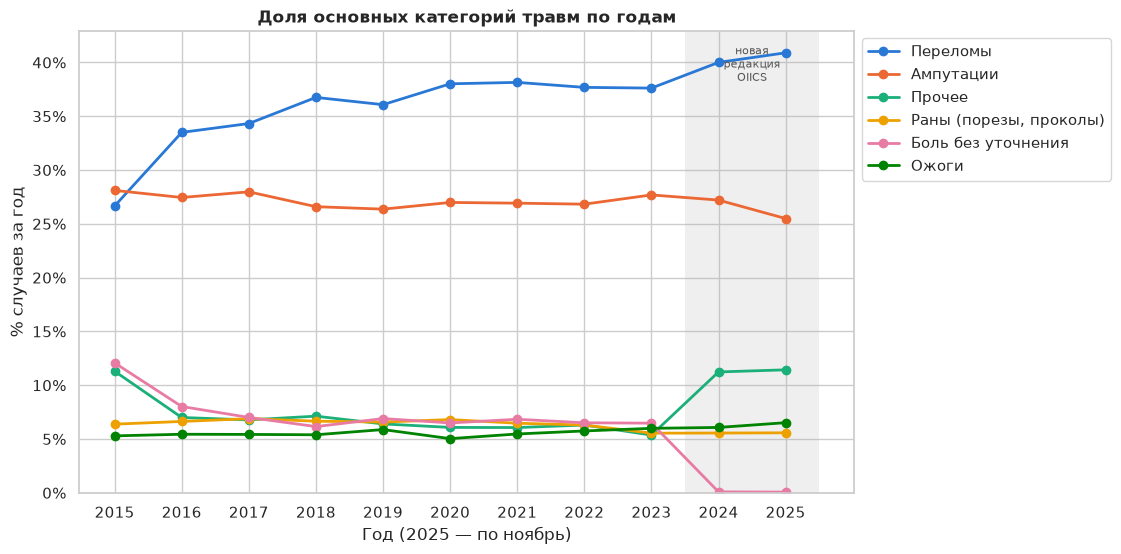

In [11]:
main = cats["category_ru"].head(6).tolist()
for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 6))
    for c, color in zip(main, SERIES):
        ax.plot(by_year.index, by_year[c], marker="o", color=color, lw=2, label=tr(c, CAT_EN[c], lang))
    ax.set_title(tr("Доля основных категорий травм по годам", "Share of main injury categories by year", lang))
    ax.set_xlabel(tr("Год (2025 — по ноябрь)", "Year (2025 — through November)", lang))
    ax.set_ylabel(tr("% случаев за год", "% of cases in year", lang))
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_xticks(by_year.index)
    ax.set_ylim(0, None)
    ax.axvspan(2023.5, 2025.5, color="#b0b0b0", alpha=0.2, lw=0)
    ax.text(2024.5, ax.get_ylim()[1] * 0.97, tr("новая\nредакция\nOIICS", "new\nOIICS\nedition", lang),
            ha="center", va="top", fontsize=8, color="#555555")
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    finish(fig, "06_5_categories_by_year", lang)

## Выводы

1. **Две трети тяжёлых травм — переломы и ампутации.** По укрупнённым категориям переломы дают 36,2%, ампутации — 27,1%; далее раны (6,3%), неуточнённая боль (6,2%), ожоги (5,7%), черепно-мозговые травмы (3,3%) и тепловой удар (2,5%). Концентрация очень высокая: 13 из 251 кода Nature покрывают 80% случаев (см. раздел 8).
2. **Ампутации — особая категория по тяжести:** госпитализированы только 30% пострадавших (у остальных категорий — 99–100%), потому что OSHA требует сообщать об ампутации отдельно, даже без госпитализации.
3. **Категория травмы тесно связана с частью тела** (V Крамера = 0,52): 95% ампутаций — верхние конечности (прежде всего кончики пальцев), 93% черепно-мозговых травм — голова, 84% внутренних повреждений — туловище, тепловой удар и электротравма почти целиком кодируются как «системы организма». Переломы чаще всего — нижние конечности (41%) и туловище (21%, в основном тазобедренная область).
4. **Категория травмы определяется типом происшествия** (V Крамера = 0,45): 94% ампутаций и 73% ран — контакт с предметами и оборудованием; 58% переломов и 63% черепно-мозговых травм — падения; 98% тепловых ударов и 70% ожогов — воздействие вредной среды.
5. **Динамика.** Структура по годам в целом устойчива (V Крамера = 0,055). На сопоставимом периоде 2016–2023 растёт доля переломов (+0,62 п.п. в год, с 33,5% до 37,6%, p = 0,006), снижаются доли «прочего» (−0,21 п.п.) и ран (−0,13 п.п. в год). Доля ампутаций стабильна (~27%, тренда нет). С 2024 года новая редакция OIICS убрала код «боль без уточнения» и объединила электротравму с электроожогами, поэтому 2024–2025 годы с предыдущими по этим категориям не сравниваются.